<a href="https://colab.research.google.com/github/devitanuraljazira/USP5/blob/main/Best_Epoch_380.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q torch-geometric rdkit pandas scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 61.8 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GCNConv, BatchNorm, global_mean_pool
from rdkit import Chem
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Configure device and seeds
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

# 1. Load and filter dataset
df_all = pd.read_csv('https://raw.githubusercontent.com/devitanuraljazira/USP5/refs/heads/main/USP5.csv')
df_clean = df_all[['Smiles', 'pIC50']].copy()
display(df_clean.head())

,Smiles,pIC50
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,O=C(NCCc1ccc(Cl)cc1)c1ccc2nc3c(c(Cl)c2c1)CCCC3,3.698970
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272


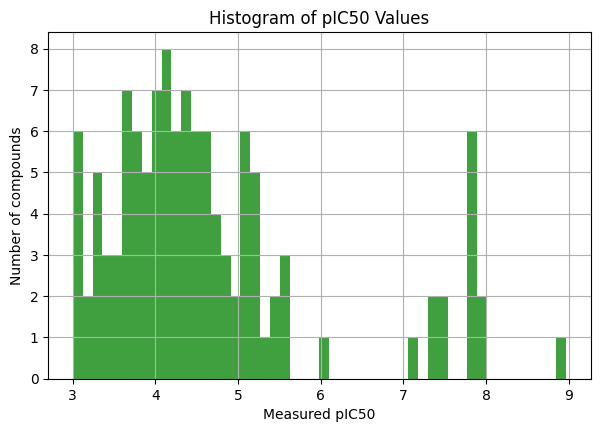

In [3]:
# 2. Plotting Target Distribution Histogram
pIC50_vals = df_clean['pIC50'].values
pIC50_vals = [val for val in pIC50_vals if val is not None and val != '']

plt.figure(figsize=(7, 4.5))
plt.hist(pIC50_vals, bins=50, facecolor='green', alpha=0.75)
plt.xlabel('Measured pIC50')
plt.ylabel('Number of compounds')
plt.title('Histogram of pIC50 Values')
plt.grid(True)
plt.show()

In [4]:
def one_hot(val, allowed):
    if val not in allowed:
        return [0] * len(allowed)
    return [1 if val == a else 0 for a in allowed]

def featurize_atom(atom):
    feats = []
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def convert_smiles_to_graph_data(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [featurize_atom(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[target]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

In [5]:
# 3. Target Standardization & Advanced Atom Featurization
y_raw_arr = df_clean['pIC50'].values.astype(np.float32)
y_mean_val = y_raw_arr.mean()
y_std_val = y_raw_arr.std()

def std_scale(y):
    return (y - y_mean_val) / (y_std_val + 1e-8)

def std_unscale(y_scaled):
    return y_scaled * y_std_val + y_mean_val

def get_atom_features_rich(atom):
    feats = []
    # Atom Symbol
    feats.extend(one_hot(atom.GetSymbol(), ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'P']))
    # Connectivity degree
    feats.extend(one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5, 6]))
    # Implicit valence
    feats.extend(one_hot(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5, 6]))
    # Hybridization
    feats.extend(one_hot(str(atom.GetHybridization()), ['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2']))
    # Rings
    feats.append(int(atom.IsInRing()))
    feats.append(int(atom.IsInRingSize(3)))
    feats.append(int(atom.IsInRingSize(5)))
    feats.append(int(atom.IsInRingSize(6)))
    # Charge & Aromaticity
    feats.append(atom.GetFormalCharge())
    feats.append(int(atom.GetIsAromatic()))
    return np.array(feats, dtype=np.float32)

def create_graph_datapoint(smiles, target):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    atom_features = [get_atom_features_rich(atom) for atom in mol.GetAtoms()]
    x = torch.tensor(np.array(atom_features), dtype=torch.float)

    edge_indices = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edge_indices.extend([[i, j], [j, i]])

    if len(edge_indices) > 0:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    y = torch.tensor([[std_scale(target)]], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, y=y)

recap_graphs = []
for _, row in df_clean.iterrows():
    graph = create_graph_datapoint(row['Smiles'], row['pIC50'])
    if graph is not None:
        recap_graphs.append(graph)

train_rec, val_rec = train_test_split(recap_graphs, test_size=0.2, random_state=42)
train_loader_rec = DataLoader(train_rec, batch_size=16, shuffle=True)
val_loader_rec = DataLoader(val_rec, batch_size=16, shuffle=False)

print(f"Featurized {len(recap_graphs)} advanced graphs successfully.")

[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:24] DEPRECATIO

Featurized 118 advanced graphs successfully.


[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[07:47:25] DEPRECATIO

In [6]:
# 4. Model Architecture & Optimization Settings
class FinalOptimizedGCN(nn.Module):
    def __init__(self, in_features):
        super(FinalOptimizedGCN, self).__init__()
        self.conv1 = GCNConv(in_features, 128)
        self.bn1 = BatchNorm(128)
        self.conv2 = GCNConv(128, 128)
        self.bn2 = BatchNorm(128)
        self.conv3 = GCNConv(128, 64)
        self.bn3 = BatchNorm(64)
        self.fc1 = nn.Linear(64, 32)
        self.dropout = nn.Dropout(p=0.1)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = F.relu(self.bn1(self.conv1(x, edge_index)))
        x = F.relu(self.bn2(self.conv2(x, edge_index)))
        x = F.relu(self.bn3(self.conv3(x, edge_index)))
        x = global_mean_pool(x, batch)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model_rec = FinalOptimizedGCN(in_features=recap_graphs[0].num_node_features).to(device)
optimizer_rec = torch.optim.AdamW(model_rec.parameters(), lr=0.005, weight_decay=1e-3)
scheduler_rec = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_rec, T_max=150)
criterion = nn.MSELoss()

In [7]:
# 5. Training Loop
train_rec_losses = []
val_rec_losses = []

for epoch in range(300):
    model_rec.train()
    train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_rec.zero_grad()
        preds = model_rec(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer_rec.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler_rec.step()

    model_rec.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            preds = model_rec(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_rec_losses.append(train_loss / len(train_rec))
    val_rec_losses.append(val_loss / len(val_rec))

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:03d} | Train Standardized MSE: {train_rec_losses[-1]:.4f} | Val Standardized MSE: {val_rec_losses[-1]:.4f}")

Epoch 015 | Train Standardized MSE: 0.2137 | Val Standardized MSE: 0.4603
Epoch 030 | Train Standardized MSE: 0.1773 | Val Standardized MSE: 0.5168
Epoch 045 | Train Standardized MSE: 0.1540 | Val Standardized MSE: 0.3735
Epoch 060 | Train Standardized MSE: 0.1586 | Val Standardized MSE: 0.2730
Epoch 075 | Train Standardized MSE: 0.0993 | Val Standardized MSE: 0.2496
Epoch 090 | Train Standardized MSE: 0.0890 | Val Standardized MSE: 0.1954
Epoch 105 | Train Standardized MSE: 0.0794 | Val Standardized MSE: 0.2330
Epoch 120 | Train Standardized MSE: 0.0865 | Val Standardized MSE: 0.2303
Epoch 135 | Train Standardized MSE: 0.0899 | Val Standardized MSE: 0.2534
Epoch 150 | Train Standardized MSE: 0.0977 | Val Standardized MSE: 0.2377
Epoch 165 | Train Standardized MSE: 0.0710 | Val Standardized MSE: 0.2363
Epoch 180 | Train Standardized MSE: 0.0773 | Val Standardized MSE: 0.2350
Epoch 195 | Train Standardized MSE: 0.0952 | Val Standardized MSE: 0.2190
Epoch 210 | Train Standardized MSE: 0.

Validation Mean Squared Error (MSE): 0.4374
Validation Mean Absolute Error (MAE): 0.4490
Validation R-squared Metric (R²): 0.7127


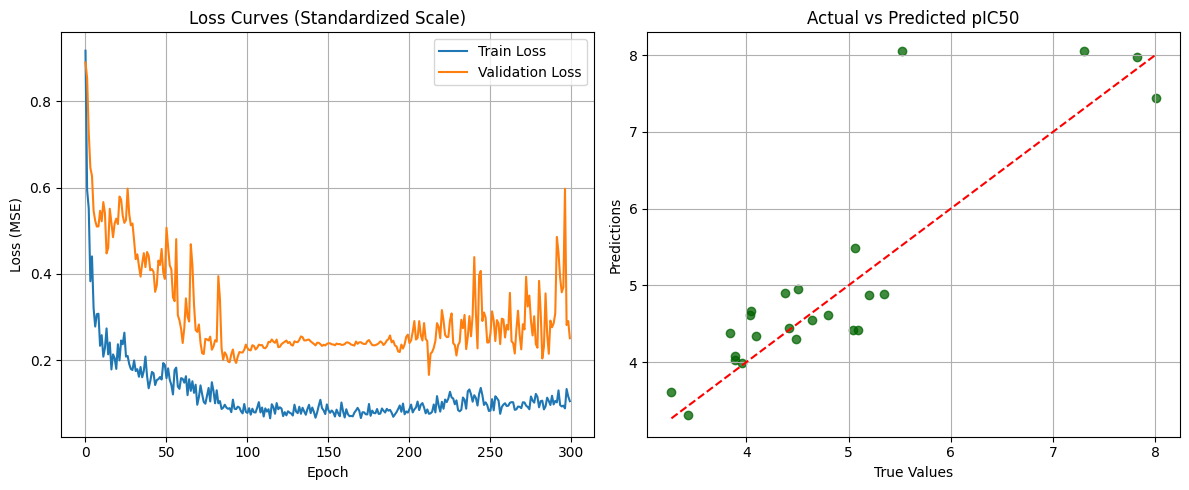

In [8]:
# 6. Performance Evaluation and Scatter Visualization
model_rec.eval()
preds_scaled = []
targets_scaled = []

with torch.no_grad():
    for batch in val_loader_rec:
        batch = batch.to(device)
        preds = model_rec(batch)
        preds_scaled.extend(preds.cpu().numpy().flatten())
        targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Rescale back to original scale
preds_unscaled = std_unscale(np.array(preds_scaled))
targets_unscaled = std_unscale(np.array(targets_scaled))

mse_final = mean_squared_error(targets_unscaled, preds_unscaled)
mae_final = np.mean(np.abs(targets_unscaled - preds_unscaled))
r2_final = r2_score(targets_unscaled, preds_unscaled)

print(f"Validation Mean Squared Error (MSE): {mse_final:.4f}")
print(f"Validation Mean Absolute Error (MAE): {mae_final:.4f}")
print(f"Validation R-squared Metric (R²): {r2_final:.4f}")

# Scatter Plot and Loss Curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_rec_losses, label='Train Loss')
plt.plot(val_rec_losses, label='Validation Loss')
plt.title('Loss Curves (Standardized Scale)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(targets_unscaled, preds_unscaled, alpha=0.75, color='darkgreen')
plt.plot([min(targets_unscaled), max(targets_unscaled)], [min(targets_unscaled), max(targets_unscaled)], 'r--')
plt.title('Actual vs Predicted pIC50')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.grid(True)

plt.tight_layout()
plt.show()

In [9]:
from torch_geometric.loader import DataLoader

# 1. Split pertama: 80% Train dan 20% Temp (untuk Val + Test)
train_rec, temp_rec = train_test_split(recap_graphs, test_size=0.20, random_state=42)

# 2. Split kedua: Bagi data Temp (20%) menjadi dua bagian yang sama (10% Val, 10% Test)
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, random_state=42)

# 3. Buat DataLoader untuk masing-masing set
train_loader_rec = DataLoader(train_rec, batch_size=16, shuffle=True)
val_loader_rec = DataLoader(val_rec, batch_size=16, shuffle=False)
test_loader_rec = DataLoader(test_rec, batch_size=16, shuffle=False)

print(f"Total data: {len(recap_graphs)}")
print(f"Jumlah data Train (80%): {len(train_rec)}")
print(f"Jumlah data Validation (10%): {len(val_rec)}")
print(f"Jumlah data Test (10%): {len(test_rec)}")

Total data: 118
Jumlah data Train (80%): 94
Jumlah data Validation (10%): 12
Jumlah data Test (10%): 12


In [11]:
# 1. Inisialisasi Ulang Model, Optimizer, Scheduler, dan Loss Function baru
model_rec = FinalOptimizedGCN(in_features=recap_graphs[0].num_node_features).to(device)
optimizer_rec = torch.optim.AdamW(model_rec.parameters(), lr=0.005, weight_decay=1e-3)
scheduler_rec = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_rec, T_max=150)
criterion = nn.MSELoss()

In [12]:
# 2. Training Loop dengan Pemantauan Validation Set Baru (10%)
train_rec_losses = []
val_rec_losses = []

for epoch in range(300):
    model_rec.train()
    train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_rec.zero_grad()
        preds = model_rec(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer_rec.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler_rec.step()

    model_rec.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            preds = model_rec(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_rec_losses.append(train_loss / len(train_rec))
    val_rec_losses.append(val_loss / len(val_rec))

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:03d} | Train Standardized MSE: {train_rec_losses[-1]:.4f} | Val Standardized MSE: {val_rec_losses[-1]:.4f}")

Epoch 015 | Train Standardized MSE: 0.2157 | Val Standardized MSE: 0.9990
Epoch 030 | Train Standardized MSE: 0.1954 | Val Standardized MSE: 0.8201
Epoch 045 | Train Standardized MSE: 0.1449 | Val Standardized MSE: 0.5763
Epoch 060 | Train Standardized MSE: 0.1495 | Val Standardized MSE: 0.7220
Epoch 075 | Train Standardized MSE: 0.1325 | Val Standardized MSE: 0.3473
Epoch 090 | Train Standardized MSE: 0.1003 | Val Standardized MSE: 0.3191
Epoch 105 | Train Standardized MSE: 0.0972 | Val Standardized MSE: 0.3305
Epoch 120 | Train Standardized MSE: 0.0795 | Val Standardized MSE: 0.3049
Epoch 135 | Train Standardized MSE: 0.0916 | Val Standardized MSE: 0.3043
Epoch 150 | Train Standardized MSE: 0.0957 | Val Standardized MSE: 0.3131
Epoch 165 | Train Standardized MSE: 0.1150 | Val Standardized MSE: 0.3140
Epoch 180 | Train Standardized MSE: 0.1109 | Val Standardized MSE: 0.3221
Epoch 195 | Train Standardized MSE: 0.0794 | Val Standardized MSE: 0.2973
Epoch 210 | Train Standardized MSE: 0.

=== HASIL EVALUASI AKHIR PADA TEST SET (10%) ===
Test Mean Squared Error (MSE): 0.2506
Test Mean Absolute Error (MAE): 0.4168
Test R-squared Metric (R%): 0.8513


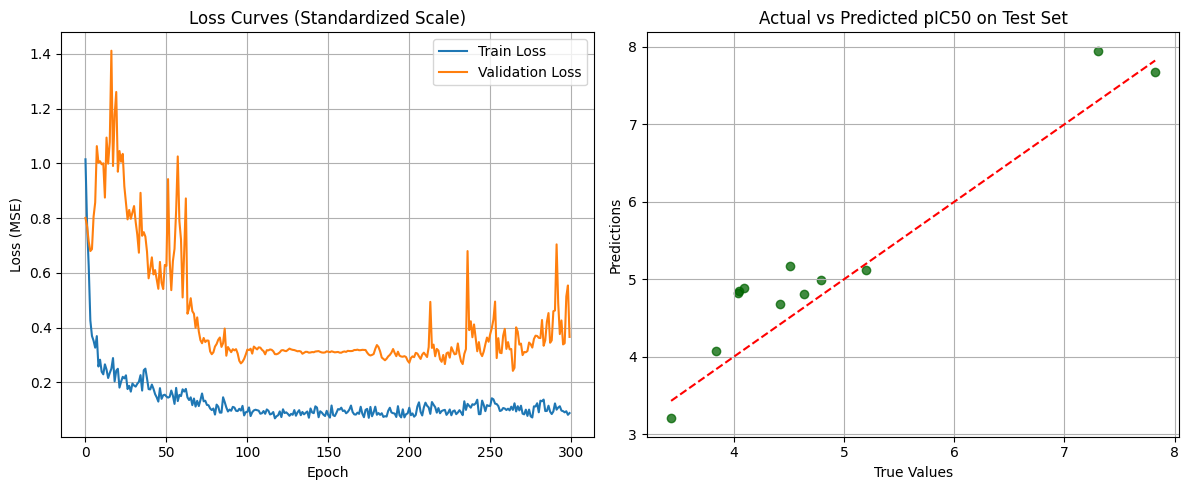

In [13]:
# 3. Evaluasi Akhir Independen Menggunakan Test Set (10%)
model_rec.eval()
preds_scaled = []
targets_scaled = []

with torch.no_grad():
    for batch in test_loader_rec: # Menggunakan test loader
        batch = batch.to(device)
        preds = model_rec(batch)
        preds_scaled.extend(preds.cpu().numpy().flatten())
        targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Kembalikan ke skala original
preds_unscaled = std_unscale(np.array(preds_scaled))
targets_unscaled = std_unscale(np.array(targets_scaled))

mse_test = mean_squared_error(targets_unscaled, preds_unscaled)
mae_test = np.mean(np.abs(targets_unscaled - preds_unscaled))
r2_test = r2_score(targets_unscaled, preds_unscaled)

print("=== HASIL EVALUASI AKHIR PADA TEST SET (10%) ===")
print(f"Test Mean Squared Error (MSE): {mse_test:.4f}")
print(f"Test Mean Absolute Error (MAE): {mae_test:.4f}")
print(f"Test R-squared Metric (R%): {r2_test:.4f}")

# Visualisasi Grafik
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_rec_losses, label='Train Loss')
plt.plot(val_rec_losses, label='Validation Loss')
plt.title('Loss Curves (Standardized Scale)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(targets_unscaled, preds_unscaled, alpha=0.75, color='darkgreen')
plt.plot([min(targets_unscaled), max(targets_unscaled)], [min(targets_unscaled), max(targets_unscaled)], 'r--')
plt.title('Actual vs Predicted pIC50 on Test Set')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.grid(True)

plt.tight_layout()
plt.show()

### Alur Rekonstruksi: Data Split -> Train (380 Epoch) -> Evaluasi Akhir

In [16]:
from torch_geometric.loader import DataLoader

# 1. Pembagian Data Ulang (80% Train, 10% Val, 10% Test)
train_rec, temp_rec = train_test_split(recap_graphs, test_size=0.20, random_state=42)
val_rec, test_rec = train_test_split(temp_rec, test_size=0.50, random_state=42)

# 2. Pembuatan DataLoader
train_loader_rec = DataLoader(train_rec, batch_size=16, shuffle=True)
val_loader_rec = DataLoader(val_rec, batch_size=16, shuffle=False)
test_loader_rec = DataLoader(test_rec, batch_size=16, shuffle=False)

print(f"Data Split Berhasil!")
print(f"Train: {len(train_rec)} | Val: {len(val_rec)} | Test: {len(test_rec)}")

Data Split Berhasil!
Train: 94 | Val: 12 | Test: 12


In [17]:
# 3. Inisialisasi Model Baru
model_380 = FinalOptimizedGCN(in_features=recap_graphs[0].num_node_features).to(device)
optimizer_380 = torch.optim.AdamW(model_380.parameters(), lr=0.005, weight_decay=1e-3)
# Atur scheduler T_max untuk tepat 380 epoch
scheduler_380 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_380, T_max=380)
criterion = nn.MSELoss()

In [18]:
# 4. Melatih Model Selama Tepat 380 Epoch
train_losses = []
val_losses = []

for epoch in range(380):
    model_380.train()
    train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_380.zero_grad()
        preds = model_380(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer_380.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler_380.step()

    model_380.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            preds = model_380(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    train_losses.append(train_loss / len(train_rec))
    val_losses.append(val_loss / len(val_rec))

    if (epoch + 1) % 50 == 0 or (epoch + 1) == 380:
        print(f"Epoch {epoch+1:03d}/380 | Train Standardized MSE: {train_losses[-1]:.4f} | Val Standardized MSE: {val_losses[-1]:.4f}")

Epoch 050/380 | Train Standardized MSE: 0.2046 | Val Standardized MSE: 1.2192
Epoch 100/380 | Train Standardized MSE: 0.1374 | Val Standardized MSE: 0.5738
Epoch 150/380 | Train Standardized MSE: 0.1272 | Val Standardized MSE: 0.4158
Epoch 200/380 | Train Standardized MSE: 0.0755 | Val Standardized MSE: 0.4318
Epoch 250/380 | Train Standardized MSE: 0.0823 | Val Standardized MSE: 0.3961
Epoch 300/380 | Train Standardized MSE: 0.0675 | Val Standardized MSE: 0.3867
Epoch 350/380 | Train Standardized MSE: 0.0875 | Val Standardized MSE: 0.3958
Epoch 380/380 | Train Standardized MSE: 0.0689 | Val Standardized MSE: 0.3920


=== HASIL EVALUASI AKHIR MODEL 380 EPOCH PADA TEST SET ===
Test Mean Squared Error (MSE): 0.1291
Test Mean Absolute Error (MAE): 0.2923
Test R-squared Metric (R²): 0.9234


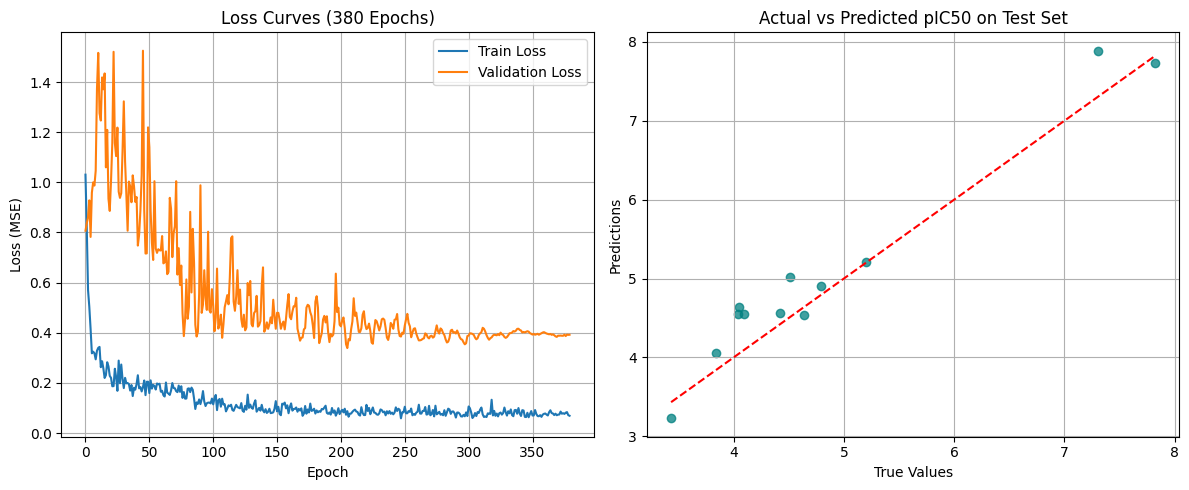

In [20]:
# 5. Evaluasi Akhir Independen Menggunakan Test Set (10%)
model_380.eval()
preds_scaled = []
targets_scaled = []

with torch.no_grad():
    for batch in test_loader_rec:
        batch = batch.to(device)
        preds = model_380(batch)
        preds_scaled.extend(preds.cpu().numpy().flatten())
        targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Kembalikan ke skala original
preds_unscaled = std_unscale(np.array(preds_scaled))
targets_unscaled = std_unscale(np.array(targets_scaled))

mse_test = mean_squared_error(targets_unscaled, preds_unscaled)
mae_test = np.mean(np.abs(targets_unscaled - preds_unscaled))
r2_test = r2_score(targets_unscaled, preds_unscaled)

print("=== HASIL EVALUASI AKHIR MODEL 380 EPOCH PADA TEST SET ===")
print(f"Test Mean Squared Error (MSE): {mse_test:.4f}")
print(f

In [14]:
import copy

# 1. Inisialisasi Ulang Model & Optimizer untuk 1000 Epoch
model_rec = FinalOptimizedGCN(in_features=recap_graphs[0].num_node_features).to(device)
optimizer_rec = torch.optim.AdamW(model_rec.parameters(), lr=0.005, weight_decay=1e-3)
# Atur scheduler T_max sesuai dengan jumlah epoch (1000)
scheduler_rec = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_rec, T_max=1000)
criterion = nn.MSELoss()

train_rec_losses = []
val_rec_losses = []

best_val_loss = float('inf')
best_epoch = -1
best_model_wts = copy.deepcopy(model_rec.state_dict())

# 2. Proses Training 1000 Epoch
for epoch in range(1000):
    model_rec.train()
    train_loss = 0
    for batch in train_loader_rec:
        batch = batch.to(device)
        optimizer_rec.zero_grad()
        preds = model_rec(batch)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer_rec.step()
        train_loss += loss.item() * batch.num_graphs

    scheduler_rec.step()

    model_rec.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader_rec:
            batch = batch.to(device)
            preds = model_rec(batch)
            loss = criterion(preds, batch.y)
            val_loss += loss.item() * batch.num_graphs

    epoch_train_loss = train_loss / len(train_rec)
    epoch_val_loss = val_loss / len(val_rec)

    train_rec_losses.append(epoch_train_loss)
    val_rec_losses.append(epoch_val_loss)

    # Simpan bobot jika ini adalah Validation Loss terbaik yang baru
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        best_model_wts = copy.deepcopy(model_rec.state_dict())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1:04d} | Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f} | Best Epoch So Far: {best_epoch} (Val MSE: {best_val_loss:.4f})")

print("\n=== TRAINING SELESAI ===")
print(f"Epoch Terbaik: {best_epoch} dengan Validation Standardized MSE: {best_val_loss:.4f}")

Epoch 0050 | Train MSE: 0.1830 | Val MSE: 0.8907 | Best Epoch So Far: 46 (Val MSE: 0.6323)
Epoch 0100 | Train MSE: 0.1102 | Val MSE: 0.4522 | Best Epoch So Far: 62 (Val MSE: 0.3483)
Epoch 0150 | Train MSE: 0.0870 | Val MSE: 0.4232 | Best Epoch So Far: 62 (Val MSE: 0.3483)
Epoch 0200 | Train MSE: 0.0896 | Val MSE: 0.4358 | Best Epoch So Far: 174 (Val MSE: 0.3218)
Epoch 0250 | Train MSE: 0.0868 | Val MSE: 0.4964 | Best Epoch So Far: 214 (Val MSE: 0.3053)
Epoch 0300 | Train MSE: 0.0716 | Val MSE: 0.3763 | Best Epoch So Far: 214 (Val MSE: 0.3053)
Epoch 0350 | Train MSE: 0.0705 | Val MSE: 0.4418 | Best Epoch So Far: 214 (Val MSE: 0.3053)
Epoch 0400 | Train MSE: 0.0969 | Val MSE: 0.4170 | Best Epoch So Far: 380 (Val MSE: 0.2906)
Epoch 0450 | Train MSE: 0.0782 | Val MSE: 0.4123 | Best Epoch So Far: 380 (Val MSE: 0.2906)
Epoch 0500 | Train MSE: 0.0733 | Val MSE: 0.3576 | Best Epoch So Far: 380 (Val MSE: 0.2906)
Epoch 0550 | Train MSE: 0.0724 | Val MSE: 0.3573 | Best Epoch So Far: 380 (Val MSE:

=== EVALUASI MODEL TERBAIK (EPOCH 380) PADA TEST SET ===
Test Mean Squared Error (MSE): 0.1834
Test Mean Absolute Error (MAE): 0.3734
Test R-squared Metric (R²): 0.8912


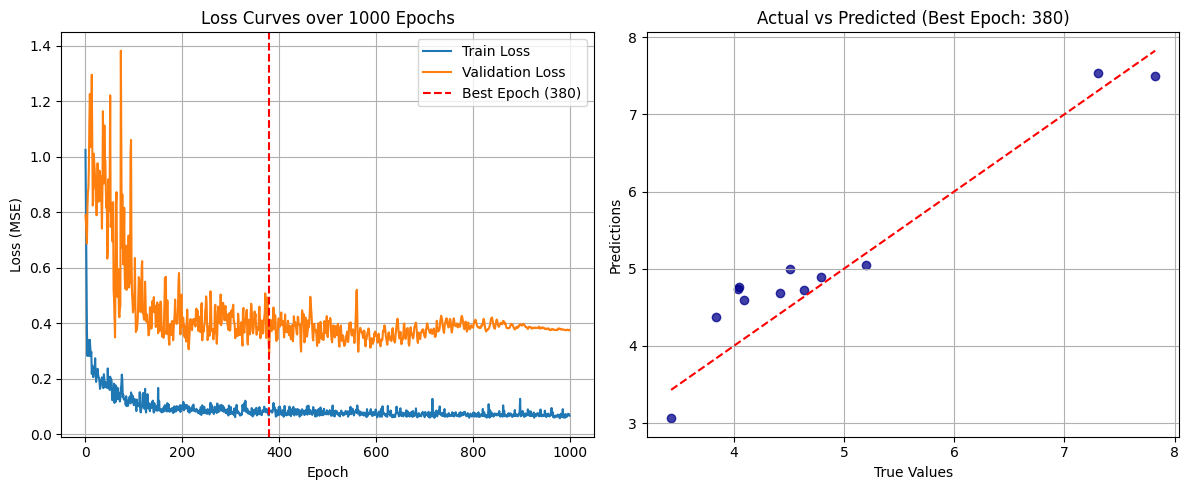

In [15]:
# 3. Load Model Terbaik dan Evaluasi pada Test Set (10%)
model_rec.load_state_dict(best_model_wts)
model_rec.eval()

preds_scaled = []
targets_scaled = []

with torch.no_grad():
    for batch in test_loader_rec:
        batch = batch.to(device)
        preds = model_rec(batch)
        preds_scaled.extend(preds.cpu().numpy().flatten())
        targets_scaled.extend(batch.y.cpu().numpy().flatten())

# Kembalikan ke skala pIC50 original
preds_unscaled = std_unscale(np.array(preds_scaled))
targets_unscaled = std_unscale(np.array(targets_scaled))

mse_test = mean_squared_error(targets_unscaled, preds_unscaled)
mae_test = np.mean(np.abs(targets_unscaled - preds_unscaled))
r2_test = r2_score(targets_unscaled, preds_unscaled)

print(f"=== EVALUASI MODEL TERBAIK (EPOCH {best_epoch}) PADA TEST SET ===")
print(f"Test Mean Squared Error (MSE): {mse_test:.4f}")
print(f"Test Mean Absolute Error (MAE): {mae_test:.4f}")
print(f"Test R-squared Metric (R²): {r2_test:.4f}")

# Visualisasi grafik performa dari 1000 Epoch
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_rec_losses, label='Train Loss')
plt.plot(val_rec_losses, label='Validation Loss')
plt.axvline(x=best_epoch-1, color='red', linestyle='--', label=f'Best Epoch ({best_epoch})')
plt.title('Loss Curves over 1000 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(targets_unscaled, preds_unscaled, alpha=0.75, color='darkblue')
plt.plot([min(targets_unscaled), max(targets_unscaled)], [min(targets_unscaled), max(targets_unscaled)], 'r--')
plt.title(f'Actual vs Predicted (Best Epoch: {best_epoch})')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.grid(True)

plt.tight_layout()
plt.show()